# Basic Probability – Simulation Exercise

**Name:** Aman Banka  **Registration No.:** 261100660030

Every experiment is simulated with NumPy, and the **experimental (empirical) probability** is compared with the **theoretical probability**:

$$P_{\text{exp}}(E) = \frac{\text{number of trials in which } E \text{ occurs}}{\text{total number of trials}}, \qquad P_{\text{theory}}(E) = \frac{|E|}{|S|}\ \text{(equally likely outcomes)}$$

A fixed random seed is used so that all outputs can be reproduced exactly.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(2026)     # reproducible random number generator
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

---
## Problem 1: A fair coin is tossed 100 times

Coding: **1 = Head**, **0 = Tail**. Each value is equally likely, so theoretically $P(H) = P(T) = 0.5$.

In [2]:
n_tosses = 100
tosses = rng.integers(0, 2, size=n_tosses)      # 1 = Head, 0 = Tail

print("First 20 tosses (1 = H, 0 = T):", tosses[:20])

num_heads = np.sum(tosses == 1)
num_tails = np.sum(tosses == 0)
p_head = num_heads / n_tosses
p_tail = num_tails / n_tosses

print(f"\nNumber of heads                    : {num_heads}")
print(f"Number of tails                    : {num_tails}")
print(f"Experimental probability of Head   : {num_heads}/{n_tosses} = {p_head:.2f}")
print(f"Experimental probability of Tail   : {num_tails}/{n_tosses} = {p_tail:.2f}")
print(f"Check: P(H) + P(T)                 = {p_head + p_tail:.2f}")

First 20 tosses (1 = H, 0 = T): [1 0 0 1 0 0 0 0 1 0 1 1 1 1 1 0 1 1 0 0]

Number of heads                    : 47
Number of tails                    : 53
Experimental probability of Head   : 47/100 = 0.47
Experimental probability of Tail   : 53/100 = 0.53
Check: P(H) + P(T)                 = 1.00


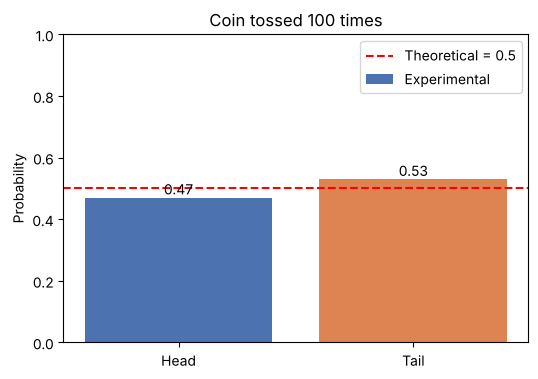

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Head", "Tail"], [p_head, p_tail], color=["#4C72B0", "#DD8452"], label="Experimental")
ax.bar_label(bars, fmt="%.2f")
ax.axhline(0.5, color="red", ls="--", label="Theoretical = 0.5")
ax.set_ylim(0, 1); ax.set_ylabel("Probability")
ax.set_title(f"Coin tossed {n_tosses} times")
ax.legend()
plt.show()

**Result:** In 100 tosses we got **47 heads** and **53 tails**, so $P_{exp}(H) = 0.47$ and $P_{exp}(T) = 0.53$. These are close to, but not exactly, the theoretical value 0.5. With only 100 tosses, random variation of a few heads either way is normal (the standard error is $\sqrt{0.5 \cdot 0.5/100} = 0.05$).

---
## Problem 2: Effect of the number of trials

The coin-toss experiment is repeated for $n = 10,\ 100,\ 1\,000,\ 10\,000$ tosses.

In [4]:
trial_sizes = [10, 100, 1_000, 10_000]
rows = []
for n in trial_sizes:
    t = rng.integers(0, 2, size=n)
    h = int(np.sum(t == 1))
    rows.append({"Number of tosses (n)": n,
                 "Heads": h,
                 "Tails": n - h,
                 "P(Head)": h / n,
                 "P(Tail)": (n - h) / n,
                 "|P(Head) - 0.5|": abs(h / n - 0.5)})
trials_table = pd.DataFrame(rows)
res2 = {r["Number of tosses (n)"]: r for r in rows}
trials_table

,Number of tosses (n),Heads,Tails,P(Head),P(Tail),|P(Head) - 0.5|
0,10,3,7,0.3000,0.7000,0.2000
1,100,52,48,0.5200,0.4800,0.0200
2,1000,486,514,0.4860,0.5140,0.0140
3,10000,5061,4939,0.5061,0.4939,0.0061


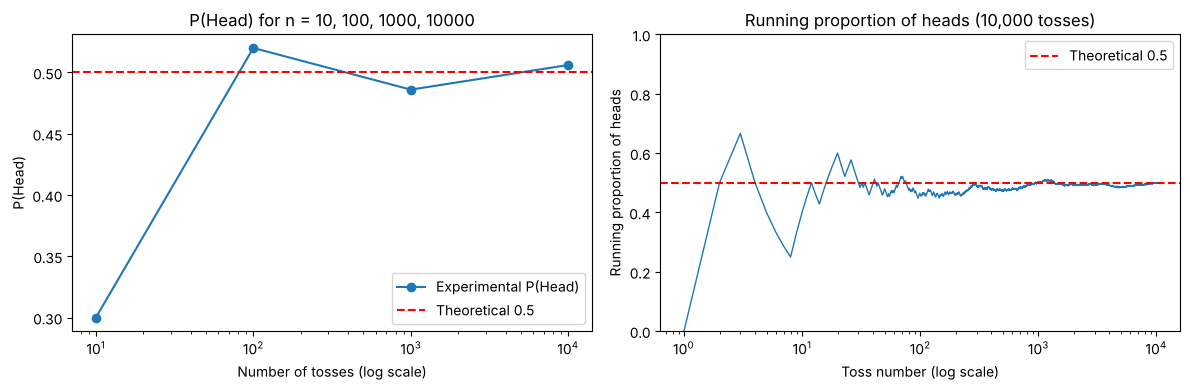

In [5]:
# Running proportion of heads over 10,000 tosses: shows convergence to 0.5
long_run = rng.integers(0, 2, size=10_000)
running_p = np.cumsum(long_run) / np.arange(1, len(long_run) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(trial_sizes, trials_table["P(Head)"], "o-", label="Experimental P(Head)")
axes[0].axhline(0.5, color="red", ls="--", label="Theoretical 0.5")
axes[0].set_xscale("log"); axes[0].set_xlabel("Number of tosses (log scale)")
axes[0].set_ylabel("P(Head)"); axes[0].set_title("P(Head) for n = 10, 100, 1000, 10000"); axes[0].legend()

axes[1].plot(np.arange(1, len(running_p) + 1), running_p, lw=1)
axes[1].axhline(0.5, color="red", ls="--", label="Theoretical 0.5")
axes[1].set_xscale("log"); axes[1].set_xlabel("Toss number (log scale)")
axes[1].set_ylabel("Running proportion of heads"); axes[1].set_ylim(0, 1)
axes[1].set_title("Running proportion of heads (10,000 tosses)"); axes[1].legend()
plt.tight_layout()
plt.show()

**Observation:** For $n = 10$, $P(H) = 0.30$. For $n = 100$ it is 0.52, for $n = 1000$ it is 0.486, and for $n = 10\,000$ it is 0.5061. With few tosses the experimental probability fluctuates a lot. As the number of trials increases, it settles closer to the theoretical value 0.5 (**Law of Large Numbers**). The running-proportion plot shows the same thing: large swings at first, then a curve that flattens around 0.5. The typical deviation shrinks like $1/\sqrt{n}$.

---
## Problem 3: Rolling a fair die 6,000 times

Sample space $S = \{1, 2, 3, 4, 5, 6\}$. Each face is equally likely, so theoretically $P(k) = 1/6 \approx 0.1667$, and each face is expected $6000/6 = 1000$ times.

In [6]:
n_rolls = 6_000
rolls = rng.integers(1, 7, size=n_rolls)        # values 1..6

faces = np.arange(1, 7)
counts = np.array([np.sum(rolls == k) for k in faces])
die_table = pd.DataFrame({
    "Outcome": faces,
    "Frequency": counts,
    "Experimental P": counts / n_rolls,
    "Theoretical P": 1 / 6,
})
die_table["Absolute difference"] = (die_table["Experimental P"] - die_table["Theoretical P"]).abs()
cmin, cmax, maxdiff = counts.min(), counts.max(), die_table["Absolute difference"].max()
print("Total rolls:", counts.sum(), "  Sum of experimental probabilities:", round((counts / n_rolls).sum(), 4))
die_table

Total rolls: 6000   Sum of experimental probabilities: 1.0


,Outcome,Frequency,Experimental P,Theoretical P,Absolute difference
0,1,1002,0.1670,0.1667,0.0003
1,2,988,0.1647,0.1667,0.0020
2,3,1006,0.1677,0.1667,0.0010
3,4,997,0.1662,0.1667,0.0005
4,5,1015,0.1692,0.1667,0.0025
5,6,992,0.1653,0.1667,0.0013


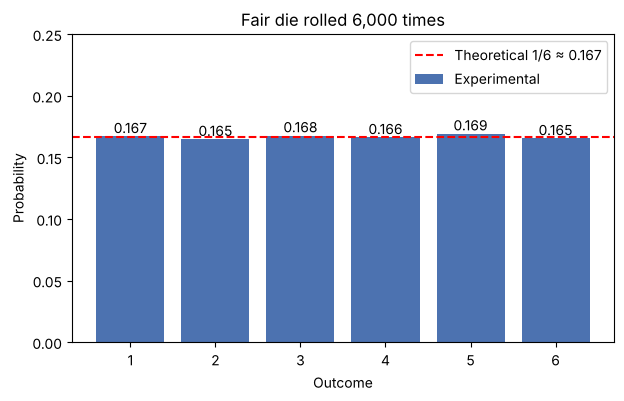

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(faces, counts / n_rolls, color="#4C72B0", label="Experimental")
ax.bar_label(bars, fmt="%.3f")
ax.axhline(1/6, color="red", ls="--", label="Theoretical 1/6 ≈ 0.167")
ax.set_xticks(faces); ax.set_xlabel("Outcome"); ax.set_ylabel("Probability")
ax.set_ylim(0, 0.25); ax.set_title("Fair die rolled 6,000 times")
ax.legend()
plt.show()

**Result:** Every face appears close to 1000 times (between 988 and 1015), so each experimental probability is close to $1/6 \approx 0.1667$. The largest deviation is 0.0025. The die behaves as a fair die, and the six probabilities add up to 1.

---
## Problem 4: Addition rule for disjoint events

A die is rolled 10,000 times. $A$ = getting 1, $B$ = getting 6, so $A = \{1\}$ and $B = \{6\}$.

**Joint or disjoint?** $A \cap B = \emptyset$, because a single roll cannot show both 1 and 6. The events are **disjoint (mutually exclusive)**, so $P(A \cap B) = 0$ and

$$P(A \cup B) = P(A) + P(B) = \tfrac16 + \tfrac16 = \tfrac13 \approx 0.3333$$

In [8]:
n4 = 10_000
r4 = rng.integers(1, 7, size=n4)

A = (r4 == 1)
B = (r4 == 6)

P_A = A.mean()
P_B = B.mean()
P_A_and_B = (A & B).mean()
P_A_or_B = (A | B).mean()
P_A_plus_B = P_A + P_B

print("Number of rolls in which both A and B occur:", np.sum(A & B), "-> events are DISJOINT")
print(f"P(A)        = {P_A:.4f}   (theory 1/6 = {1/6:.4f})")
print(f"P(B)        = {P_B:.4f}   (theory 1/6 = {1/6:.4f})")
print(f"P(A ∩ B)    = {P_A_and_B:.4f}   (theory 0)")
print(f"P(A ∪ B)    = {P_A_or_B:.4f}   (counted directly)")
print(f"P(A) + P(B) = {P_A + P_B:.4f}")
print("Addition rule P(A ∪ B) = P(A) + P(B) holds:", np.isclose(P_A_or_B, P_A + P_B))

Number of rolls in which both A and B occur: 0 -> events are DISJOINT
P(A)        = 0.1680   (theory 1/6 = 0.1667)
P(B)        = 0.1624   (theory 1/6 = 0.1667)
P(A ∩ B)    = 0.0000   (theory 0)
P(A ∪ B)    = 0.3304   (counted directly)
P(A) + P(B) = 0.3304
Addition rule P(A ∪ B) = P(A) + P(B) holds: True


**Verified:** $P(A \cup B)$ counted directly (0.3304) is **exactly equal** to $P(A) + P(B)$ (0.3304), and both are close to the theoretical $1/3$. For disjoint events no roll is counted twice, so the counts simply add.

---
## Problem 5: Addition rule for overlapping events

For one die roll: $A$ = even number $= \{2,4,6\}$ and $B$ = number greater than 3 $= \{4,5,6\}$. The events **overlap**: $A \cap B = \{4, 6\}$ and $A \cup B = \{2,4,5,6\}$.

Theory: $P(A) = \tfrac36$, $P(B) = \tfrac36$, $P(A\cap B) = \tfrac26$, so

$$P(A \cup B) = P(A) + P(B) - P(A\cap B) = \tfrac36 + \tfrac36 - \tfrac26 = \tfrac46 \approx 0.6667$$

The number of rolls is not given in the question, so 10,000 rolls are simulated (the same as Problem 4).

In [9]:
n5 = 10_000
r5 = rng.integers(1, 7, size=n5)

A = np.isin(r5, [2, 4, 6])     # even number
B = r5 > 3                     # greater than 3 -> {4, 5, 6}

P_A, P_B = A.mean(), B.mean()
P_A_and_B = (A & B).mean()
P_A_or_B = (A | B).mean()
rhs = P_A + P_B - P_A_and_B
P_A_or_B5, rhs5, naive5 = P_A_or_B, rhs, P_A + P_B

overlap = pd.DataFrame({
    "Quantity": ["P(A)", "P(B)", "P(A ∩ B)", "P(A ∪ B) (direct count)",
                 "P(A) + P(B) - P(A ∩ B)", "P(A) + P(B)  (without subtracting overlap)"],
    "Experimental": [P_A, P_B, P_A_and_B, P_A_or_B, rhs, P_A + P_B],
    "Theoretical": [3/6, 3/6, 2/6, 4/6, 4/6, 1.0],
})
print("Rolls in which A and B both occur:", np.sum(A & B), "-> events OVERLAP (not disjoint)")
print("Addition rule P(A ∪ B) = P(A) + P(B) - P(A ∩ B) holds:", np.isclose(P_A_or_B, rhs))
overlap

Rolls in which A and B both occur: 3278 -> events OVERLAP (not disjoint)
Addition rule P(A ∪ B) = P(A) + P(B) - P(A ∩ B) holds: True


,Quantity,Experimental,Theoretical
0,P(A),0.4970,0.5000
1,P(B),0.4968,0.5000
2,P(A ∩ B),0.3278,0.3333
3,P(A ∪ B) (direct count),0.6660,0.6667
4,P(A) + P(B) - P(A ∩ B),0.6660,0.6667
5,P(A) + P(B) (without subtracting overlap),0.9938,1.0000


**Verified:** The direct count gives $P(A \cup B) = 0.6660$, which is **exactly equal** to $P(A) + P(B) - P(A\cap B) = 0.6660$, and both are close to the theoretical $2/3$. Simply adding $P(A) + P(B)$ would give about 0.9938 (theory: 1). That double-counts the outcomes 4 and 6, which belong to both events, so the intersection must be subtracted once.

---
## Problem 6: Multiplication rule for independent events

A coin is tossed **and** a die is rolled, 10,000 times. $A$ = obtaining a Head, $B$ = obtaining an even number on the die.

The coin and the die are physically separate, so the outcome of one has no effect on the other. $A$ and $B$ are **independent**:

$$P(A \cap B) = P(A)\,P(B) = \tfrac12 \times \tfrac12 = \tfrac14 = 0.25$$

In [10]:
n6 = 10_000
coin = rng.integers(0, 2, size=n6)      # 1 = Head
die = rng.integers(1, 7, size=n6)

A = (coin == 1)            # Head
B = (die % 2 == 0)         # even number

P_A, P_B = A.mean(), B.mean()
P_A_and_B = (A & B).mean()
product = P_A * P_B
P_AB6, prod6, diff6 = P_A_and_B, product, abs(P_A_and_B - product)

print(f"P(A) = P(Head)          = {P_A:.4f}   (theory 0.5)")
print(f"P(B) = P(Even)          = {P_B:.4f}   (theory 0.5)")
print(f"P(A ∩ B) (direct count) = {P_A_and_B:.4f}   (theory 0.25)")
print(f"P(A) × P(B)             = {product:.4f}")
print(f"Absolute difference     = {abs(P_A_and_B - product):.4f}")

# The four joint outcomes (contingency table of proportions)
joint = pd.crosstab(np.where(A, "Head", "Tail"), np.where(B, "Even", "Odd"),
                    normalize=True, rownames=["Coin"], colnames=["Die"])
joint

P(A) = P(Head)          = 0.4956   (theory 0.5)
P(B) = P(Even)          = 0.4957   (theory 0.5)
P(A ∩ B) (direct count) = 0.2460   (theory 0.25)
P(A) × P(B)             = 0.2457
Absolute difference     = 0.0003


Die,Even,Odd
Coin,,
Head,0.2460,0.2496
Tail,0.2497,0.2547


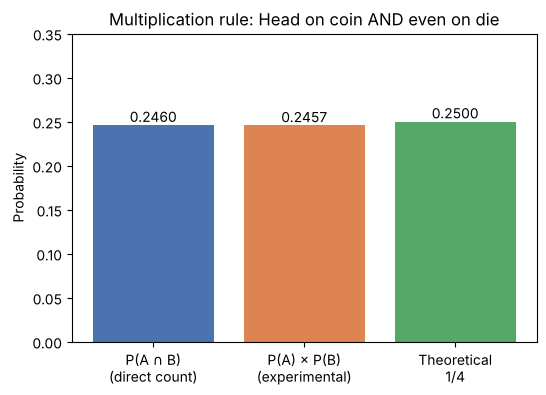

In [11]:
fig, ax = plt.subplots(figsize=(6, 4))
vals = [P_A_and_B, product, 0.25]
bars = ax.bar(["P(A ∩ B)\n(direct count)", "P(A) × P(B)\n(experimental)", "Theoretical\n1/4"], vals,
              color=["#4C72B0", "#DD8452", "#55A868"])
ax.bar_label(bars, fmt="%.4f")
ax.set_ylim(0, 0.35); ax.set_ylabel("Probability")
ax.set_title("Multiplication rule: Head on coin AND even on die")
plt.show()

**Verified:** $P(A \cap B) = 0.2460$ and $P(A)P(B) = 0.2457$. They differ by only 0.0003, and both are close to the theoretical 0.25. Unlike the addition rule, the two sides are not identical in a finite experiment, because $P(A)P(B)$ is a product of two separately estimated proportions. The agreement is within normal sampling error (about $\sqrt{0.25 \cdot 0.75/10000} \approx 0.004$), which confirms that the coin and die are independent. All four joint outcomes (H-Even, H-Odd, T-Even, T-Odd) occur about 25 % of the time.

---
## Learnings from this exercise

1. **Experimental vs theoretical probability.** Experimental probability is a relative frequency from actual trials. Theoretical probability comes from equally likely outcomes, $|E|/|S|$. In a finite experiment the two are close but usually not identical (100 tosses gave $P(H) = 0.47$, not exactly 0.5).
2. **Law of Large Numbers.** As the number of trials grows (10 → 100 → 1,000 → 10,000), the experimental probability settles closer to the theoretical value. Small samples fluctuate a lot, and the error shrinks roughly like $1/\sqrt{n}$.
3. **Equally likely outcomes.** For 6,000 rolls of a fair die, each face appeared about 1,000 times, with probability ≈ 1/6. The probabilities of all outcomes in the sample space add to 1.
4. **Disjoint events.** Events that cannot happen together ($A$ = 1, $B$ = 6) have $P(A\cap B) = 0$, so $P(A\cup B) = P(A) + P(B)$.
5. **Overlapping events.** When events share outcomes ($A$ = even, $B$ = >3 share 4 and 6), adding $P(A) + P(B)$ counts the overlap twice. The correct rule subtracts it once: $P(A\cup B) = P(A) + P(B) - P(A\cap B)$. The addition rules hold *exactly* even for experimental frequencies, because they are counting identities.
6. **Independent events.** For a coin and a die, one outcome gives no information about the other, so $P(A\cap B) = P(A)P(B)$. In simulation this holds only *approximately*, within sampling error.
7. **Simulation as a tool.** With NumPy (`rng.integers`, Boolean masks, `&` for intersection, `|` for union, `.mean()` for proportions), probability rules can be checked numerically in a few lines. Using a seed makes the results reproducible.